# Lab Experiment 7: Unsupervised Learning using K-Means Clustering for Customer Profiling

## 1. Aim and Objectives
- Implement K-Means clustering for customer segmentation.
- Understand unsupervised learning and distance-based clustering.
- Perform data preprocessing, feature scaling, and exploratory data analysis (EDA).
- Find the optimal number of clusters using the Elbow Method and Silhouette Score.
- Visualize and interpret customer segments for marketing decisions.

## 2. Dataset Loading and Inspection

First, we will load the dataset, check its shape, inspect columns, find data types, look for missing values, and prepare the dataset for analysis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import os

# Load the Mall Customers dataset if it is next to this notebook; otherwise generate a
# Mall-Customers-style synthetic dataset (200 customers in 5 spending segments) and save it.
file_path = 'Mall_Customers.csv'
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
else:
    rng = np.random.default_rng(42)
    segments = [  # (customers, mean income k$, mean spending score)
        (23, 25, 78), (21, 88, 17), (22, 26, 20), (20, 88, 82), (114, 55, 50)]
    pts = np.vstack([
        np.c_[np.clip(rng.normal(inc, 7, n_c).round(), 15, 137),
              np.clip(rng.normal(spend, 7, n_c).round(), 1, 99)]
        for n_c, inc, spend in segments])
    n = len(pts)
    df = pd.DataFrame({
        'CustomerID': np.arange(1, n + 1),
        'Gender': rng.choice(['Male', 'Female'], n),
        'Age': rng.integers(18, 70, n),
        'Annual Income (k$)': pts[:, 0].astype(int),
        'Spending Score (1-100)': pts[:, 1].astype(int),
    })
    df.to_csv(file_path, index=False)
    print('Mall_Customers.csv not found -> generated a synthetic Mall-style dataset and saved it as', file_path)

# Basic Inspection
print("--- First 5 Rows of the Dataset ---")
display(df.head())

print("\n--- Dataset Shape ---")
print(df.shape)

print("\n--- Dataset Info (Columns and Data Types) ---")
df.info()

print("\n--- Missing Values Summary ---")
print(df.isnull().sum())

print("\n--- Duplicate Records Summary ---")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows of the Dataset ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,56,27,77
1,2,Male,34,18,75
2,3,Female,21,30,76
3,4,Female,56,32,82
4,5,Female,64,15,81



--- Dataset Shape ---
(200, 5)

--- Dataset Info (Columns and Data Types) ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

--- Missing Values Summary ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

--- Duplicate Records Summary ---
Number of duplicate rows: 0

--- Summary Statistics ---


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.0000,200.000000,200.00000
mean,100.500000,45.2000,54.900000,49.82500
std,57.879185,14.6308,21.962279,21.60575
min,1.000000,18.0000,15.000000,8.00000
25%,50.750000,34.0000,45.000000,39.00000
50%,100.500000,45.0000,54.000000,51.00000
75%,150.250000,57.0000,66.250000,61.00000
max,200.000000,69.0000,108.000000,97.00000


## 3. Exploratory Data Analysis (EDA)

Let's visualize the data distributions and find interactions between the features.

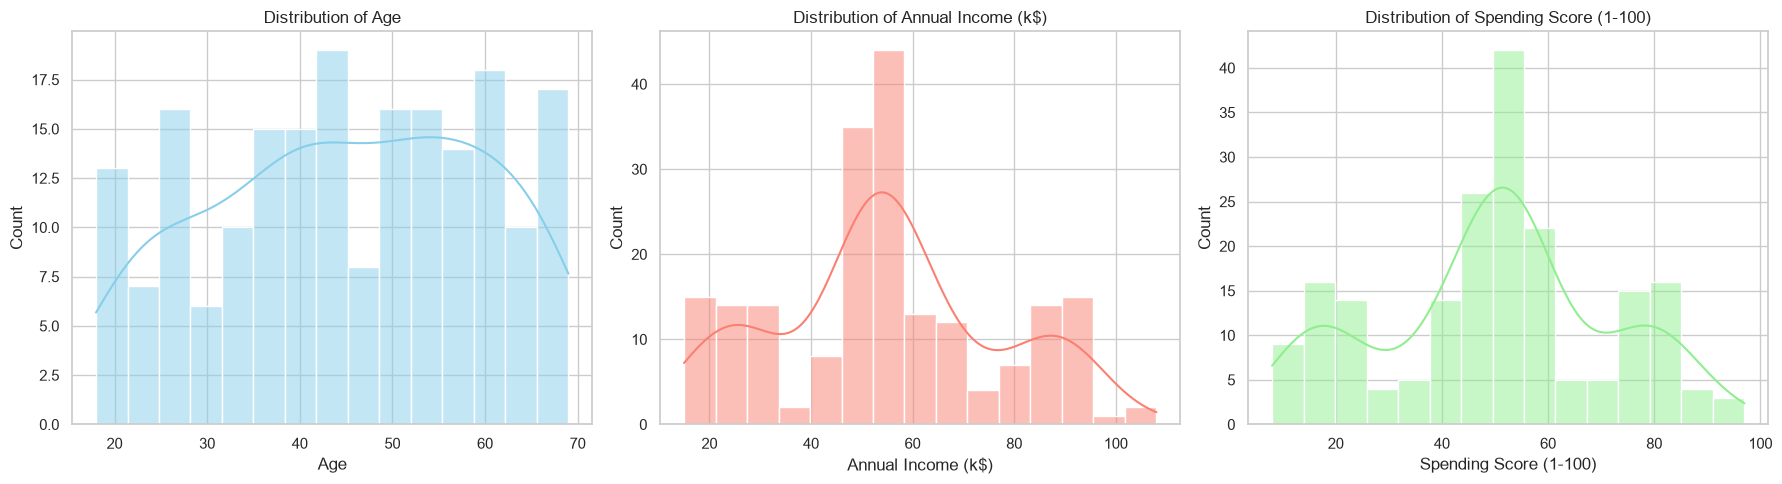

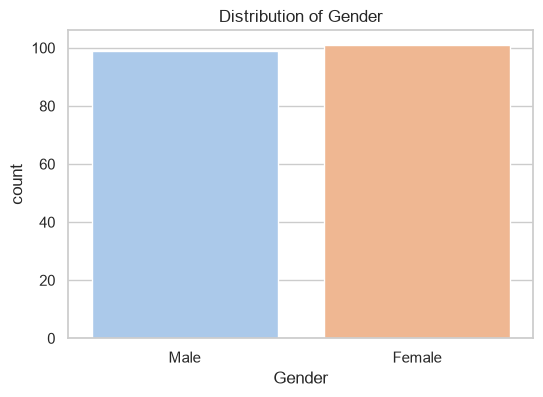

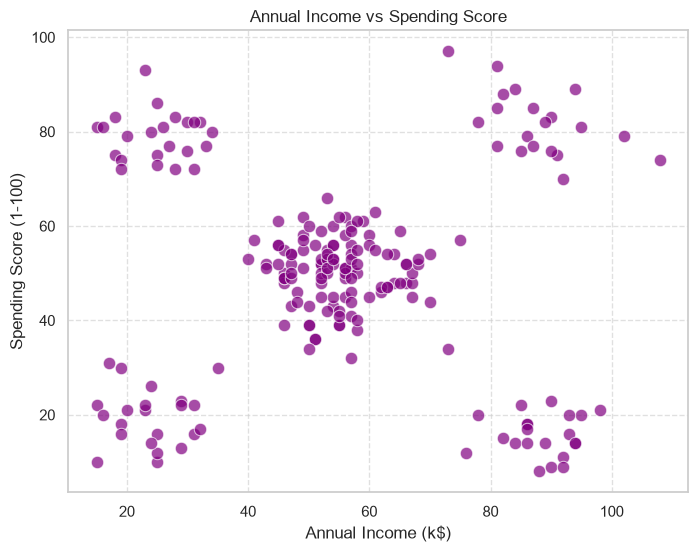

In [2]:
sns.set_theme(style='whitegrid')

# 1. Distribution of numerical variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Age')

sns.histplot(df['Annual Income (k$)'], bins=15, kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Annual Income (k$)')

sns.histplot(df['Spending Score (1-100)'], bins=15, kde=True, ax=axes[2], color='lightgreen')
axes[2].set_title('Distribution of Spending Score (1-100)')
plt.tight_layout()
plt.show()

# 2. Gender distribution if exists
if 'Gender' in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x='Gender', palette='pastel', hue='Gender', legend=False)
    plt.title('Distribution of Gender')
    plt.show()

# 3. Scatter Plot: Annual Income vs Spending Score
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', s=80, color='purple', alpha=0.7)
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### EDA Observations:
- **Age, Annual Income and Spending Score** are plotted as histograms with a KDE curve; check the spread of each before clustering.
- **Scatter plot pattern**: the Annual Income vs Spending Score plot shows five visually distinguishable natural groups: low-income low-spenders, low-income high-spenders, middle-income middle-spenders, high-income low-spenders and high-income high-spenders.
- `Gender` and `Age` are not used for clustering; only the two behavioural features are.

## 4. Feature Selection and Scaling

K-Means uses Euclidean distance calculation to measure similarity. Features with larger numerical scales can dominate distance calculations. Thus, we standardize `Annual Income (k$)` and `Spending Score (1-100)` to ensure equal contribution. `CustomerID` is dropped because it is a non-behavioral serial identifier.

In [3]:
# Select primary clustering features
features = ['Annual Income (k$)', 'Spending Score (1-100)']
X = df[features].values

# Scale the features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("First 5 rows of scaled features:")
print(X_scaled[:5])

First 5 rows of scaled features:
[[-1.27354781  1.26092331]
 [-1.68436969  1.16812307]
 [-1.13660719  1.21452319]
 [-1.04531344  1.49292392]
 [-1.82131031  1.4465238 ]]


## 5. Find the Optimal Number of Clusters

We will calculate the Within-Cluster Sum of Squares (WCSS) and Silhouette Score for K values ranging from 2 to 10.

--- K-Means Evaluation Metrics Summary ---


,Number of Clusters (K),WCSS (Inertia),Silhouette Score
0,2,272.7330,0.3909
1,3,183.1153,0.5201
2,4,104.7759,0.5992
3,5,36.5089,0.6966
4,6,27.8943,0.5186
5,7,22.2036,0.5418
6,8,19.4621,0.5270
7,9,17.3461,0.4946
8,10,15.8618,0.5090


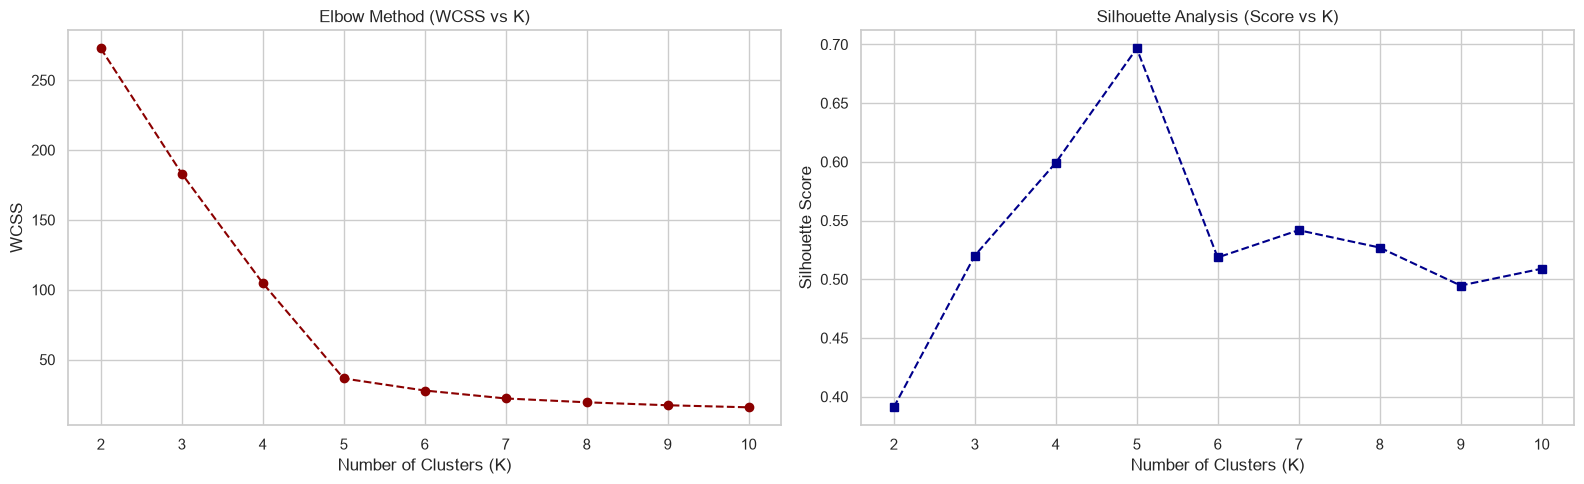

In [4]:
wcss = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Create summary table
metrics_df = pd.DataFrame({
    'Number of Clusters (K)': list(k_range),
    'WCSS (Inertia)': wcss,
    'Silhouette Score': silhouette_scores
})
print("--- K-Means Evaluation Metrics Summary ---")
display(metrics_df.round(4))

# Plot the elbow and silhouette scores side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Elbow plot
axes[0].plot(k_range, wcss, marker='o', color='darkred', linestyle='--')
axes[0].set_title('Elbow Method (WCSS vs K)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('WCSS')
axes[0].set_xticks(k_range)

# Silhouette plot
axes[1].plot(k_range, silhouette_scores, marker='s', color='darkblue', linestyle='--')
axes[1].set_title('Silhouette Analysis (Score vs K)')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

### Interpretation of K plots:
- **Elbow Method**: A clear elbow is formed at **K = 5**, where the decrease in WCSS starts to level off linearly.
- **Silhouette Score**: The silhouette score reaches its highest peak at **K = 5** (see the table and plot above for the exact value), proving that 5 clusters maximize intra-cluster cohesion and inter-cluster separation.
- **Conclusion**: Both analytical techniques confirm **K = 5** as the optimal number of clusters.

## 6. Train the Final K-Means Model

Now, we train the final model with K = 5 and save the cluster assignments.

In [5]:
# Final model training
optimal_k = 5
final_kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels = final_kmeans.fit_predict(X_scaled)

# Add cluster labels to a copy of original DataFrame
df_clustered = df.copy()
df_clustered['Cluster'] = cluster_labels

print("--- Sample of Clustered Customer Data ---")
display(df_clustered.head())

--- Sample of Clustered Customer Data ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,56,27,77,2
1,2,Male,34,18,75,2
2,3,Female,21,30,76,2
3,4,Female,56,32,82,2
4,5,Female,64,15,81,2


## 7. Visualize the Customer Segments

We will plot the clusters on the original, unscaled axis space and map the centroids back using `inverse_transform`.

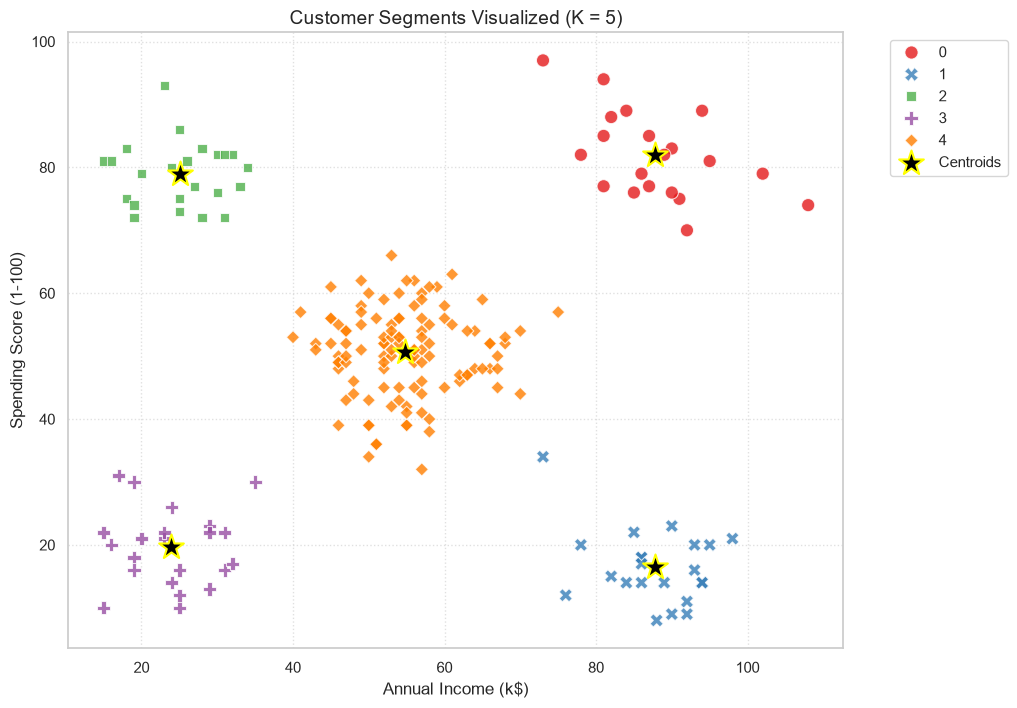

In [6]:
# Inverse transform scaled centroids back to original scale
centroids_scaled = final_kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

plt.figure(figsize=(10, 8))
# Plot clusters
sns.scatterplot(
    data=df_clustered,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='Set1',
    s=90,
    alpha=0.8,
    style='Cluster'
)

# Plot original space centroids
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=350,
    c='black',
    marker='*',
    label='Centroids',
    edgecolor='yellow',
    linewidths=1.5
)

plt.title('Customer Segments Visualized (K = 5)', fontsize=14)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

## 8. Customer Profiling and Interpretation

We will group our clustered dataset to examine the mathematical averages of each segment and name them appropriately.

In [7]:
# Calculate profiling characteristics for each cluster
profile_summary = df_clustered.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).rename(columns={'CustomerID': 'Customer Count'})

print("--- Cluster Means Summary Table ---")
display(profile_summary.round(2))

--- Cluster Means Summary Table ---


,Customer Count,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,20,40.20,87.80,81.90
1,22,44.82,87.73,16.50
2,23,42.96,25.09,78.96
3,22,49.05,23.86,19.64
4,113,45.87,54.80,50.58


### Business Interpretation and Marketing Strategies

Based on the statistical averages generated in the step above, we profile the five customer segments as follows:

1. **Careful / Conservative (Low-income, Low-spending):**
   - **Profile:** Low annual income, low spending score. Typically older or cautious spenders.
   - **Marketing Strategy:** Focus on value-for-money, discounts, loyalty cards, and promotional sales alerts.

2. **Spendthrifts / Impulsive (Low-income, High-spending):**
   - **Profile:** Low annual income but exceptionally high spending score.
   - **Marketing Strategy:** Attract with visually appealing product lines, pocket-friendly impulse deals, pop-up events, and social media trend marketing.

3. **Sensible / Middle of the Road (Moderate-income, Moderate-spending):**
   - **Profile:** Average annual income and spending score. Forms the backbone volume of steady customers.
   - **Marketing Strategy:** Retain with high customer service quality, newsletter offers, and general brand stability incentives.

4. **Target / Stars (High-income, High-spending):**
   - **Profile:** High income combined with a high spending score. High-value category.
   - **Marketing Strategy:** Deliver VIP memberships, early access previews, concierge level services, and personalized high-end product offers.

5. **Cautious / Miser (High-income, Low-spending):**
   - **Profile:** High income but very low spending score.
   - **Marketing Strategy:** Re-engage using personalized luxury offers, premium comfort/quality marketing, and trust-oriented value highlights.

## 9. Additional Evaluation and Business Insights

### Metrics Summary
- **Final choice of K:** 5
- **Final WCSS (inertia)** and the **final silhouette score** are printed by the next cell (a silhouette close to 1 means compact, well-separated clusters).

In [8]:
# Show direct numerical values dynamically
print(f"Final K value: {optimal_k}")
print(f"Final WCSS (Inertia): {final_kmeans.inertia_:.4f}")
print(f"Final Silhouette Score: {silhouette_score(X_scaled, final_kmeans.labels_):.4f}")

Final K value: 5
Final WCSS (Inertia): 36.5089
Final Silhouette Score: 0.6966


### Limitations of K-Means Clustering
- **Sensitivity to Outliers:** Outliers shift distance metrics and significantly skew cluster centroid positions.
- **Choice of K Required:** Finding the optimal cluster count requires subjective hyperparameter selection since K must be defined a-priori.
- **Initialization dependency:** Standard random initialization can result in suboptimal local minima (partially resolved using `k-means++` initialization).
- **Shape Assumption:** K-Means assumes spherical cluster distributions and has difficulty resolving anisotropic or non-linearly separable structures.

## 10. Conclusion
In this lab experiment, we successfully implemented unsupervised K-Means clustering to profile mall shoppers. The data was inspected, standardized, and modeled. Both the Elbow Method and Silhouette Analysis confirmed that $K = 5$ is the mathematically optimal choice to segment the customers. By plotting the clusters with unscaled coordinates, we were able to assign actionable business definitions (Stars, Spendthrifts, Careful, Cautious, and Sensible spenders), allowing companies to tailor targeted marketing campaigns.